# 03 -- Template mismatch: what happens when the library doesn't match the galaxy

**Goal:** every fit so far (`01_basic_mock_fit.ipynb`,
`02_realistic_mock_fit.ipynb`) built its mock and its fitting library from
the *same* templates -- the honest, best-case scenario. A real galaxy is
never built from your template library; it's built from actual stars, and
your library is only ever an approximation to them. This notebook shows,
directly, what happens to the recovered LOSVD when that approximation is
a poor one: fit the *same* mock spectrum with a template library that
actually contains the true stellar population, and with one that
systematically does not, and compare.

This isn't a corner case -- it's the normal situation for real data, and
it motivates `04_template_calibration.ipynb`, which builds a principled
way to check whether a candidate library is a good match to a specific
real spectrum *before* trusting the kinematics it recovers.

## 1. Setup, and a mock built from one specific stellar population

The true galaxy here is a single, specific stellar population -- young
and metal-poor (1 Gyr, [M/H]=-0.66) -- broadened by a known LOSVD. Using
one population (rather than a mixture) keeps the story clean: any bias
below is entirely attributable to how well each *library* can represent
*this one population*, not to a separate mixture-recovery question
(`01_basic_mock_fit.ipynb`'s Section 6 already covers mixture recovery on
its own).

In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

from kinextract import (
    FitConfig, build_template_stack, build_spline_truth, compute_losvd_moments,
    load_emiles_templates,
)
from kinextract.multi_template import fit_losvd

EMILES_GRID = "../../src/kinextract/template_data/emiles_muse_grid.npz"
WAVEFITMIN, WAVEFITMAX = 8400.0, 8800.0  # CaII triplet region, this package's MUSE convention
observed_wavelength = 4750.0 + np.arange(3681) * 1.25
wave_fit = observed_wavelength[(observed_wavelength >= WAVEFITMIN) & (observed_wavelength <= WAVEFITMAX)]

TRUE_V, TRUE_SIGMA, SNR = 0.0, 90.0, 80.0
TRUE_AGE, TRUE_METAL = 1.0, -0.66  # young, metal-poor -- the actual (unknown, in a real fit) population

cfg = FitConfig(vmin=TRUE_V - 7 * TRUE_SIGMA, vmax=TRUE_V + 7 * TRUE_SIGMA)
v_grid = cfg.build_velocity_grid()
b_truth, _ = build_spline_truth(v_grid, vel=TRUE_V, sigma=TRUE_SIGMA, wiggle_scale=0.0, seed=7)
b_truth_n = b_truth / np.trapezoid(b_truth, v_grid)

true_templates, template_wave, *_ = load_emiles_templates(EMILES_GRID, select=[(TRUE_AGE, TRUE_METAL)])
A_true = build_template_stack(wave_fit, template_wave, true_templates, v_grid)
galaxy_noiseless = A_true[0] @ b_truth
noise_level = np.median(galaxy_noiseless) / SNR
rng = np.random.default_rng(1)
galaxy = galaxy_noiseless + rng.normal(0.0, noise_level, len(wave_fit))
errors = np.full(len(wave_fit), noise_level)

print(f"true population: age={TRUE_AGE:.1f} Gyr, [M/H]={TRUE_METAL:+.2f}")
print(f"true LOSVD: V={TRUE_V:+.0f} km/s, sigma={TRUE_SIGMA:.0f} km/s, S/N~{SNR:.0f}")


true population: age=1.0 Gyr, [M/H]=-0.66
true LOSVD: V=+0 km/s, sigma=90 km/s, S/N~80


## 2. Fit with a matched library

The fitting library below *includes* the true population (age=1 Gyr,
[M/H]=-0.66), alongside a couple of others spanning a broader age/
metallicity range -- a realistic library, not a single-template fit
rigged to trivially succeed.

In [2]:
MATCHED_RECIPE = [(1.0, -0.66), (5.0, 0.06), (14.0, 0.40)]  # includes the true population


def fit_and_report(select, label):
    templates, twave, names, ages, metals = load_emiles_templates(EMILES_GRID, select=select)
    A_stack = build_template_stack(wave_fit, twave, templates, v_grid)
    A_stack_w = A_stack / errors[None, :, None]
    y_w = galaxy / errors
    result = fit_losvd(A_stack_w, y_w, cfg)
    m = compute_losvd_moments(v_grid, result['b'], fit_h3h4=True)
    A_eff = np.tensordot(result['w'], A_stack_w, axes=([0], [0]))
    chi2_red = float(np.sum((A_eff @ result['b'] - y_w) ** 2)) / len(wave_fit)
    b_fit_n = result['b'] / np.trapezoid(np.maximum(result['b'], 0.0), v_grid)
    print(f"{label}: library={[f'{a:.1f}/{z:+.2f}' for a, z in select]}")
    print(f"  V={m['vherm']:+.1f} km/s (true {TRUE_V:+.0f}),  sigma={m['sherm']:.1f} km/s (true {TRUE_SIGMA:.0f}),  "
          f"h3={m['h3']:+.3f}, h4={m['h4']:+.3f},  chi2_red={chi2_red:.2f}")
    return dict(result=result, moments=m, b_fit_n=b_fit_n, chi2_red=chi2_red, names=names)


matched = fit_and_report(MATCHED_RECIPE, "Matched library")


Matched library: library=['1.0/-0.66', '5.0/+0.06', '14.0/+0.40']
  V=+1.6 km/s (true +0),  sigma=92.1 km/s (true 90),  h3=-0.000, h4=+0.000,  chi2_red=0.84


## 3. Fit with a mismatched library

The fitting library below is deliberately built entirely from *old,
metal-rich* populations -- nothing resembling the true young, metal-poor
population is available. NNLS still returns *some* nonnegative mixture
(it always can -- `nnls` doesn't fail just because every candidate is a
poor match), so nothing in the fit's own diagnostics obviously "refuses"
to run. The only visible sign of trouble, absent a ground truth to
compare against, is `chi2_red` -- watch it below.

In [3]:
MISMATCHED_RECIPE = [(9.0, 0.06), (11.0, 0.40), (14.0, 0.40)]  # no young/metal-poor population at all

mismatched = fit_and_report(MISMATCHED_RECIPE, "Mismatched library")


Mismatched library: library=['9.0/+0.06', '11.0/+0.40', '14.0/+0.40']
  V=+13.7 km/s (true +0),  sigma=129.8 km/s (true 90),  h3=+0.019, h4=+0.004,  chi2_red=2.71


## 4. Compare directly

The spectral fit quality (`chi2_red`) already flags that something is
wrong with the mismatched library -- but the more important comparison is
the recovered *LOSVD curve* itself, not just that one number, since a
real fit's `chi2_red` doesn't come with a "true" curve to check against.

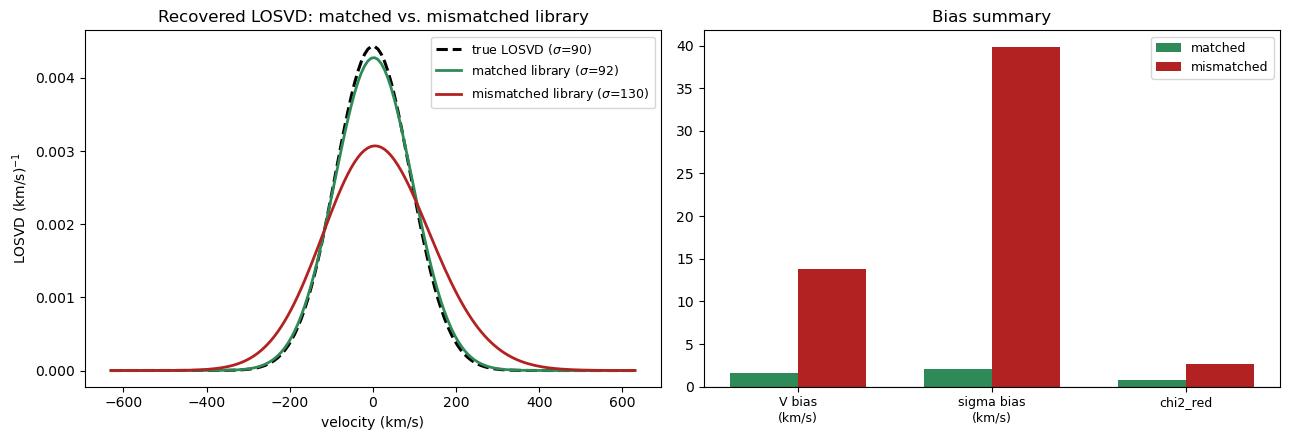

                        V bias   sigma bias  chi2_red
             matched      +1.6         +2.1      0.84
          mismatched     +13.7        +39.8      2.71


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.plot(v_grid, b_truth_n, color='black', lw=2.2, ls='--', label=fr'true LOSVD ($\sigma$={TRUE_SIGMA:.0f})')
ax.plot(v_grid, matched['b_fit_n'], color='seagreen', lw=2.0,
        label=fr"matched library ($\sigma$={matched['moments']['sherm']:.0f})")
ax.plot(v_grid, mismatched['b_fit_n'], color='firebrick', lw=2.0,
        label=fr"mismatched library ($\sigma$={mismatched['moments']['sherm']:.0f})")
ax.set_xlabel('velocity (km/s)'); ax.set_ylabel(r'LOSVD (km/s)$^{-1}$')
ax.set_title('Recovered LOSVD: matched vs. mismatched library')
ax.legend(fontsize=9)

ax = axes[1]
labels = ['V bias\n(km/s)', 'sigma bias\n(km/s)', 'chi2_red']
matched_vals = [matched['moments']['vherm'] - TRUE_V, matched['moments']['sherm'] - TRUE_SIGMA, matched['chi2_red']]
mismatched_vals = [mismatched['moments']['vherm'] - TRUE_V, mismatched['moments']['sherm'] - TRUE_SIGMA, mismatched['chi2_red']]
x = np.arange(3)
width = 0.35
ax.bar(x - width / 2, matched_vals, width, label='matched', color='seagreen')
ax.bar(x + width / 2, mismatched_vals, width, label='mismatched', color='firebrick')
ax.axhline(0, lw=0.8, color='k')
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
ax.set_title('Bias summary')
ax.legend(fontsize=9)

plt.tight_layout(); plt.show()

print(f"{'':>20}{'V bias':>10}{'sigma bias':>13}{'chi2_red':>10}")
print(f"{'matched':>20}{matched['moments']['vherm']-TRUE_V:>+10.1f}"
      f"{matched['moments']['sherm']-TRUE_SIGMA:>+13.1f}{matched['chi2_red']:>10.2f}")
print(f"{'mismatched':>20}{mismatched['moments']['vherm']-TRUE_V:>+10.1f}"
      f"{mismatched['moments']['sherm']-TRUE_SIGMA:>+13.1f}{mismatched['chi2_red']:>10.2f}")


## 5. Why this happens

The fit has no way to know the true population isn't in its library --
it only ever sees the *residual* between the data and whatever mixture of
its own templates fits best. When every available template's own
intrinsic line shapes/depths differ systematically from the true
population's, the optimizer's only remaining lever to reduce that
residual is the LOSVD itself: broadening or narrowing $b(v)$, or shifting
its center, can partially compensate for a shape mismatch that has
nothing to do with kinematics at all. A free parameter absorbing whatever
the "correct" parameter can't (or, here, doesn't get the chance to)
explain is a recurring failure mode in this kind of joint fit -- the same
underlying pattern shows up again, in a different guise, in
`02_realistic_mock_fit.ipynb`'s continuum-cofitting section.

**This is exactly why `04_template_calibration.ipynb` exists.** Comparing
`chi2_red` alone isn't enough (a mismatched library still converges, still
returns a nonnegative mixture, and the value above degrading is a hint but
not a diagnosis) -- what's needed is a way to actively check *which*
populations a real spectrum's own residuals suggest are missing or
wrong, before trusting the kinematics a library recovers. That's the
subject of the next notebook.

## Conclusion

**What this notebook did.** Fit the same mock spectrum -- one true
stellar population, a known LOSVD -- with two different template
libraries: one that includes the true population, one that doesn't come
close to it anywhere. The matched library recovered $V$ and $\sigma$
close to truth; the mismatched one did not, despite NNLS still returning
a valid, nonnegative mixture and the fit still formally "succeeding."

**Key takeaways:**

- A template library that doesn't contain (or resemble) the true stellar
  population biases the recovered LOSVD, because the LOSVD is the only
  free parameter left to absorb a spectral shape mismatch the templates
  themselves can't explain.
- `chi2_red` is a hint that something is wrong, not a diagnosis of what --
  it rose here because this mock's mismatch is severe and S/N is high
  enough to show it clearly; a smaller mismatch or noisier data can hide
  behind a `chi2_red` that still looks acceptable.
- Nothing in the fit's own success flag or NNLS output distinguishes a
  well-matched library from a badly mismatched one. This has to be
  checked separately, against the specific data at hand.

**Next**: `04_template_calibration.ipynb` builds a principled, data-driven
way to check which stellar populations a real spectrum's own residuals
actually support, before trusting the kinematics any library recovers
from it -- the direct answer to the problem this notebook demonstrates.

See `kinextract.multi_template`'s own module docstring for the NNLS
weight-solving mechanism referenced above, and `kinextract.lsf`'s for a
related but separate failure mode (instrument-resolution mismatch) not
covered here.